In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import joblib

from pathlib import Path


In [4]:
df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0


In [6]:
df.columns = df.columns.str.strip()

df = df.drop_duplicates()

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Annual Income (k$)"] = pd.to_numeric(
    df["Annual Income (k$)"], errors="coerce"
)
df["Spending Score (1-100)"] = pd.to_numeric(
    df["Spending Score (1-100)"], errors="coerce"
)

df = df.dropna(
    subset=[
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
)

print("Data cleaning completed!")
print("Remaining rows:", len(df))
print(df.head())

Data cleaning completed!
Remaining rows: 200
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [7]:
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features]

print("Selected features:")
print(X.head())

Selected features:
   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40


In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardization completed!")
print("Scaled data shape:", X_scaled.shape)

Standardization completed!
Scaled data shape: (200, 3)


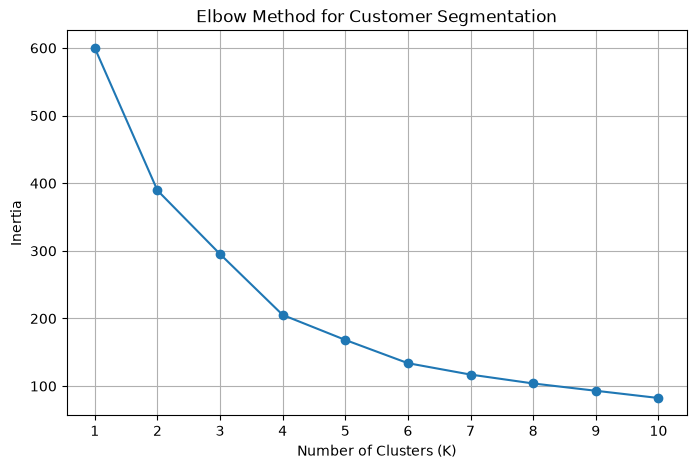

In [9]:
inertia_values = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o")
plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.savefig("elbow_method.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print(df[["Age", "Annual Income (k$)",
          "Spending Score (1-100)", "Cluster"]].head(10))

K-Means clustering completed!
   Age  Annual Income (k$)  Spending Score (1-100)  Cluster
0   19                  15                      39        0
1   21                  15                      81        0
2   20                  16                       6        0
3   23                  16                      77        0
4   31                  17                      40        0
5   22                  17                      76        0
6   35                  18                       6        0
7   23                  18                      94        0
8   64                  19                       3        2
9   30                  19                      72        0


In [11]:
score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.3578


In [12]:
cluster_spending = df.groupby("Cluster")[
    "Spending Score (1-100)"
].mean()

sorted_clusters = cluster_spending.sort_values().index.tolist()

segment_names = {
    sorted_clusters[0]: "Low Spenders",
    sorted_clusters[1]: "Medium Spenders",
    sorted_clusters[2]: "High Spenders"
}

df["Segment"] = df["Cluster"].map(segment_names)

print(df[["Cluster", "Segment"]].head(10))

   Cluster          Segment
0        0  Medium Spenders
1        0  Medium Spenders
2        0  Medium Spenders
3        0  Medium Spenders
4        0  Medium Spenders
5        0  Medium Spenders
6        0  Medium Spenders
7        0  Medium Spenders
8        2     Low Spenders
9        0  Medium Spenders


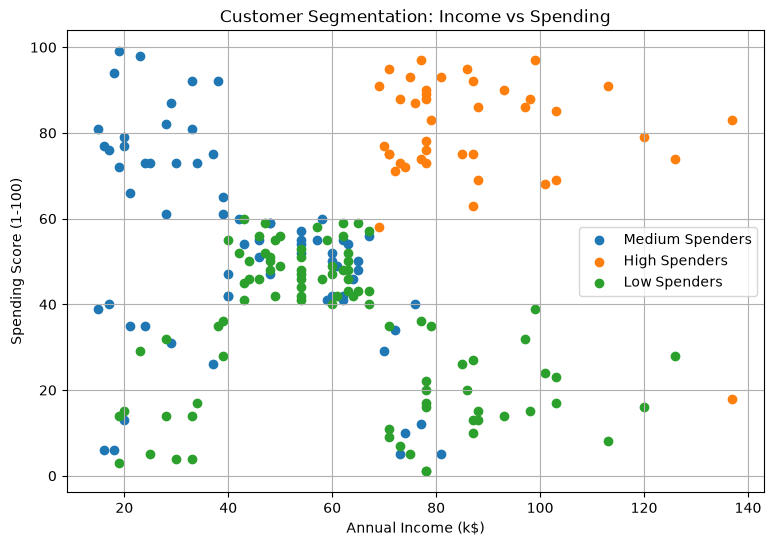

In [13]:
plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=segment_names[cluster]
    )

plt.title("Customer Segmentation: Income vs Spending")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True)
plt.savefig(
    "customer_segments_income_spending.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

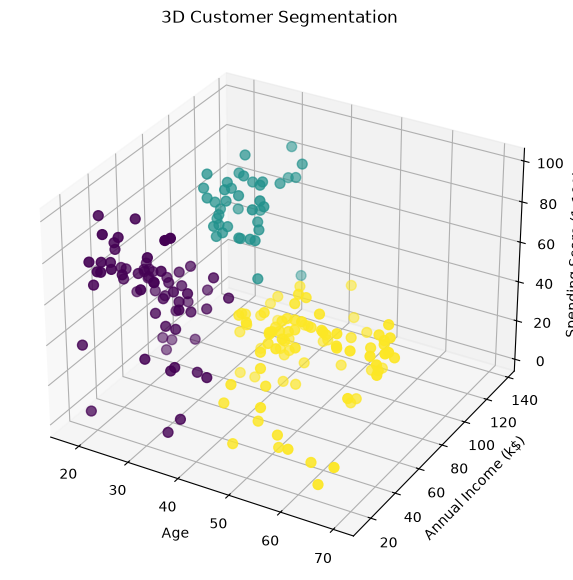

In [14]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    df["Age"],
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    s=50
)

ax.set_title("3D Customer Segmentation")
ax.set_xlabel("Age")
ax.set_ylabel("Annual Income (k$)")
ax.set_zlabel("Spending Score (1-100)")

plt.savefig(
    "customer_segments_3d.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [15]:
summary = df.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print(summary)

summary.to_csv("customer_segment_summary.csv")
print("\nSegment summary saved!")

                 Customer_Count  Average_Age  Average_Income  \
Segment                                                        
High Spenders                41        32.85           87.34   
Low Spenders                 91        51.27           61.80   
Medium Spenders              68        25.84           42.75   

                 Average_Spending_Score  
Segment                                  
High Spenders                     79.98  
Low Spenders                      34.21  
Medium Spenders                   53.65  

Segment summary saved!


In [16]:
df.to_csv("customer_segmentation_results.csv", index=False)

print("Customer segmentation results saved!")

Customer segmentation results saved!


In [17]:
model_data = {
    "scaler": scaler,
    "kmeans": kmeans,
    "features": features,
    "segment_names": segment_names
}

joblib.dump(model_data, "customer_segmentation_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [18]:
loaded_model = joblib.load("customer_segmentation_model.joblib")

sample = df[features].iloc[[0]]

sample_scaled = loaded_model["scaler"].transform(sample)

prediction = loaded_model["kmeans"].predict(sample_scaled)[0]

print("Predicted cluster:", prediction)
print("Predicted segment:", loaded_model["segment_names"][prediction])

Predicted cluster: 0
Predicted segment: Medium Spenders
